### Exercise 1

Gel electrophoresis is an analysis method used in all disciplines of the life sciences.
The results of gel electrophoresis indicate the relative sizes of the fragments, which is useful for restriction mapping and for analyzing PCR fragments.

1. Take an arbitrary DNA sequence from NCBI (National Center for Biotechnology Information), between 1000 and 3000 nucleotides (letters).
2. Take 10 random samples from this sequence, between 100 and 3000 bases.
3. Store these samples in an array.
4. Simulate the migration of these DNA segments on the electrophoresis gel, based on their molecular weight (number of nucleotides).

**Note:** Short DNA fragments meet small friction forces and travel fast through the electrophoresis gel, while long DNA fragments exhibit a high friction force and travel slowly through the gel.

Sequence used: *Cloning vector pUC19c*, complete sequence (NCBI **L09137.2**, 2,686 bp).

In [1]:
# Step 1: Load the sequence from puc19.fasta
import random

with open("puc19.fasta") as f:
    dna_seq = "".join(line.strip() for line in f if not line.startswith(">")).upper()

print("Sequence: Cloning vector pUC19c (NCBI L09137.2)")
print(f"Sequence length = {len(dna_seq):,} bp")

# Step 2 & 3: Take 10 random samples between 100 and 3000 bases and store in an array
random.seed(42)
num_samples = 10
samples = []
for i in range(num_samples):
    length = random.randint(100, min(3000, len(dna_seq)))
    start = random.randint(0, len(dna_seq) - length)
    samples.append(dna_seq[start:start + length])

sample_lengths = [len(s) for s in samples]

print(f"\nGenerated {len(samples)} random samples stored in array:")
print(f"{'Sample':<8} {'Length (bp)':<13} {'Preview (first 40 bases)':<45}")
print("-" * 70)
for i, s in enumerate(samples, 1):
    print(f"{i:<8} {len(s):<13} {s[:40]}...")


Sequence: Cloning vector pUC19c (NCBI L09137.2)
Sequence length = 2,686 bp

Generated 10 random samples stored in array:
Sample   Length (bp)   Preview (first 40 bases)                     
----------------------------------------------------------------------
1        556           AGGGCGCGTCAGCGGGTGTTGGCGGGTGTCGGGGCTGGCT...
2        1226          ACAATTCCACACAACATACGAGCCGGAAGCATAAAGTGTA...
3        1014          GGGCCTCTTCGCTATTACGCCAGCTGGCGAAAGGGGGATG...
4        519           GGGTTTTCCCAGTCACGACGTTGTAAAACGACGGCCAGTG...
5        2518          CGTCAGCGGGTGTTGGCGGGTGTCGGGGCTGGCTTAACTA...
6        230           GGCGGGTGTCGGGGCTGGCTTAACTATGCGGCATCAGAGC...
7        483           ATCACAAAAATCGACGCTCAAGTCAGAGGTGGCGAAACCC...
8        1052          CCCTTCGGGAAGCGTGGCGCTTTCTCATAGCTCACGCTGT...
9        2565          CGCGTTTCGGTGATGACGGTGAAAACCTCTGACACATGCA...
10       2398          CAGGGCGCGTCAGCGGGTGTTGGCGGGTGTCGGGGCTGGC...


#### Molecular weight of each fragment

On the gel the fragments are double-stranded DNA, so the molecular weight is approximately

$$MW_{dsDNA} \approx N_{bp} \times 617.96 + 36.04 \ \text{g/mol}$$

The weight is proportional to the number of base pairs, so the size in bp is what decides the migration speed.

In [2]:
# Calculate double-stranded DNA molecular weight:
# MW_dsDNA ≈ N_bp * 617.96 + 36.04 g/mol
def molecular_weight_dsdna(num_bp):
    return num_bp * 617.96 + 36.04

sample_weights = [molecular_weight_dsdna(n) for n in sample_lengths]

print(f"{'Sample':<8} {'Length (bp)':<13} {'Molecular Weight (g/mol)':<26}")
print("-" * 50)
for i, (n, mw) in enumerate(zip(sample_lengths, sample_weights), 1):
    print(f"{i:<8} {n:<13} {mw:<26,.2f}")


Sample   Length (bp)   Molecular Weight (g/mol)  
--------------------------------------------------
1        556           343,621.80                
2        1226          757,655.00                
3        1014          626,647.48                
4        519           320,757.28                
5        2518          1,556,059.32              
6        230           142,166.84                
7        483           298,510.72                
8        1052          650,129.96                
9        2565          1,585,103.44              
10       2398          1,481,904.12              


#### Migration model

In an agarose gel the distance travelled by a linear DNA fragment decreases (approximately linearly) with the
**logarithm** of its size: the larger the fragment, the more friction it meets in the pores of the gel, so the slower it moves.
We use

$$v(N) = k \cdot (\log_{10} N_{max} - \log_{10} N), \qquad d(t) = v(N) \cdot t$$

where $N_{max} = 20\,000$ bp is a size that practically does not move and $k$ is set so that the smallest fragment of the
ladder (100 bp) reaches the bottom of the gel at the end of the run. A DNA ladder (fragments of known size) is run in the first lane, like in a real experiment.

In [3]:
# Gel electrophoresis migration model
import numpy as np

N_max = 20000.0   # bp: threshold above which linear fragments are nearly immobile
d_bottom = 100.0  # mm: distance to bottom of gel

# Ladder fragments (bp)
ladder_bp = [100, 250, 500, 750, 1000, 1500, 2000, 3000]

# Calibration: smallest ladder fragment (100 bp) reaches bottom of gel (d_bottom)
k_calib = d_bottom / (np.log10(N_max) - np.log10(100.0))

def migration_distance(n_bp):
    return k_calib * (np.log10(N_max) - np.log10(n_bp))

ladder_dist = [migration_distance(bp) for bp in ladder_bp]
sample_dist = [migration_distance(n) for n in sample_lengths]

print(f"Migration constant k = {k_calib:.3f}")
print("\nLadder calibration:")
for bp, dist in zip(ladder_bp, ladder_dist):
    print(f"  Ladder {bp:4d} bp -> distance = {dist:6.2f} mm")

print("\nSample migration distances:")
for i, (n, dist) in enumerate(zip(sample_lengths, sample_dist), 1):
    print(f"  Sample {i:2d}: {n:4d} bp -> distance = {dist:6.2f} mm")


Migration constant k = 43.459

Ladder calibration:
  Ladder  100 bp -> distance = 100.00 mm
  Ladder  250 bp -> distance =  82.71 mm
  Ladder  500 bp -> distance =  69.62 mm
  Ladder  750 bp -> distance =  61.97 mm
  Ladder 1000 bp -> distance =  56.54 mm
  Ladder 1500 bp -> distance =  48.89 mm
  Ladder 2000 bp -> distance =  43.46 mm
  Ladder 3000 bp -> distance =  35.81 mm

Sample migration distances:
  Sample  1:  556 bp -> distance =  67.62 mm
  Sample  2: 1226 bp -> distance =  52.70 mm
  Sample  3: 1014 bp -> distance =  56.28 mm
  Sample  4:  519 bp -> distance =  68.92 mm
  Sample  5: 2518 bp -> distance =  39.11 mm
  Sample  6:  230 bp -> distance =  84.28 mm
  Sample  7:  483 bp -> distance =  70.28 mm
  Sample  8: 1052 bp -> distance =  55.58 mm
  Sample  9: 2565 bp -> distance =  38.76 mm
  Sample 10: 2398 bp -> distance =  40.03 mm


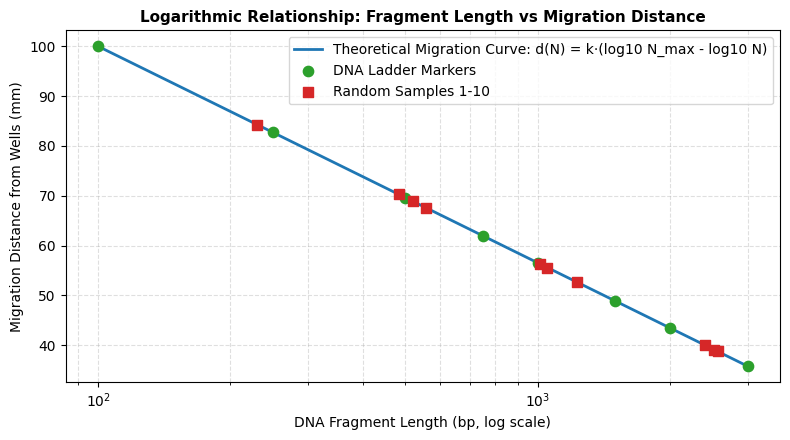

In [4]:
# Visualize distance vs fragment size (logarithmic migration curve)
import matplotlib.pyplot as plt

curve_bp = np.logspace(np.log10(100), np.log10(3000), 200)
curve_dist = migration_distance(curve_bp)

plt.figure(figsize=(8, 4.5))
plt.plot(curve_bp, curve_dist, color='#1f77b4', lw=2, label='Theoretical Migration Curve: d(N) = k·(log10 N_max - log10 N)')
plt.scatter(ladder_bp, ladder_dist, color='#2ca02c', s=55, zorder=5, label='DNA Ladder Markers')
plt.scatter(sample_lengths, sample_dist, color='#d62728', s=50, marker='s', zorder=5, label='Random Samples 1-10')

plt.xscale('log')
plt.xlabel('DNA Fragment Length (bp, log scale)', fontsize=10)
plt.ylabel('Migration Distance from Wells (mm)', fontsize=10)
plt.title('Logarithmic Relationship: Fragment Length vs Migration Distance', fontsize=11, fontweight='bold')
plt.grid(True, which='both', linestyle='--', alpha=0.4)
plt.legend(frameon=True)
plt.tight_layout()
plt.show()


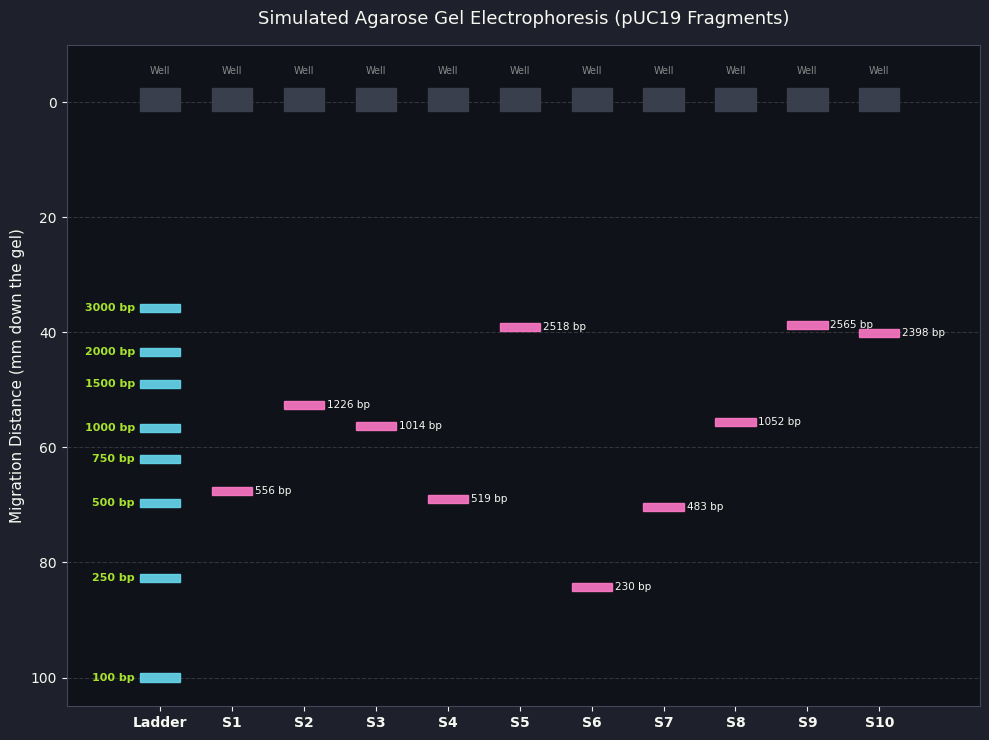

In [5]:
# Simulate migration on an electrophoresis gel
plt.figure(figsize=(10, 7.5))
ax = plt.gca()
ax.set_facecolor('#10121a')
plt.gcf().patch.set_facecolor('#1e212b')

lanes = ['Ladder'] + [f'S{i}' for i in range(1, 11)]
x_coords = np.arange(len(lanes))

# Draw sample loading wells at top (y = 0)
for x in x_coords:
    ax.add_patch(plt.Rectangle((x - 0.28, -2.5), 0.56, 4, color='#3a3f4d', zorder=2))
    ax.text(x, -5, 'Well', color='#888888', fontsize=7, ha='center')

# Draw ladder bands (Lane 0)
for bp, dist in zip(ladder_bp, ladder_dist):
    ax.add_patch(plt.Rectangle((-0.28, dist - 0.7), 0.56, 1.4, color='#66d9ef', alpha=0.9, zorder=3))
    ax.text(-0.35, dist, f'{bp} bp', color='#a6e22e', fontsize=8, ha='right', va='center', fontweight='bold')

# Draw sample bands (Lanes 1 to 10)
for i, (n, dist) in enumerate(zip(sample_lengths, sample_dist), 1):
    ax.add_patch(plt.Rectangle((i - 0.28, dist - 0.7), 0.56, 1.4, color='#ff79c6', alpha=0.9, zorder=3))
    ax.text(i + 0.32, dist, f'{n} bp', color='#f8f8f2', fontsize=7.5, ha='left', va='center')

ax.set_xlim(-1.3, len(lanes) + 0.4)
ax.set_ylim(105, -10)  # Invert y-axis: 0 at top (wells), 100 at bottom
ax.set_xticks(x_coords)
ax.set_xticklabels(lanes, color='#f8f8f2', fontsize=10, fontweight='bold')
ax.set_ylabel('Migration Distance (mm down the gel)', color='#f8f8f2', fontsize=11)
ax.set_title('Simulated Agarose Gel Electrophoresis (pUC19 Fragments)', color='#f8f8f2', fontsize=13, pad=15)
ax.tick_params(colors='#f8f8f2')
ax.grid(axis='y', linestyle='--', alpha=0.15, color='#ffffff')
for spine in ax.spines.values():
    spine.set_color('#44475a')

plt.tight_layout()
plt.show()


### Conclusion

From our gel simulation and calculations:

1. **Smaller fragments travel much farther:** Sample 6 (230 bp) migrated 84.3 mm, while Sample 9 (2565 bp) barely reached 38.8 mm. This happens because smaller fragments easily pass through agarose pores with minimal friction.
2. **Separation is logarithmic, not linear:** Looking at our ladder and gel, fragments between 100-500 bp are spaced far apart (100 to 69.6 mm), whereas large fragments like Sample 5 (2518 bp) and Sample 9 (2565 bp) sit almost on top of each other (~39 mm). That makes distinguishing large fragments of similar size difficult on a standard gel.
3. **Ladder acts as a visual ruler:** By matching our sample bands against the known ladder bands, we can estimate any unknown fragment size directly from its migration distance.


### Exercise 2

Take an arbitrary DNA sequence from NCBI, between 1000 and 3000 nucleotides. Implement a software application that
detects **repetitions between 6 and 10 bases** in the DNA sequence. The length of the repeated unit is between **3 and 5** bases.

Sequence used: the same *Cloning vector pUC19c* (NCBI **L09137.2**, 2,686 bp) from Exercise 1.

#### Approach

We look for **tandem repeats**: a unit of 3-5 bases that is copied right after itself, so that the whole repeated
region has 6-10 bases:

| Unit length | Copies | Region length | Example |
|:-:|:-:|:-:|:--|
| 3 | 2 or 3 | 6 or 9 | `ACG ACG`, `ACG ACG ACG` |
| 4 | 2 | 8 | `CTCA CTCA` |
| 5 | 2 | 10 | `TTGCG TTGCG` |

For each unit length $u = 3, 4, 5$ we move along the sequence, take the $u$ bases starting at position $i$ as the unit and
count how many times it is copied back to back. If there are at least 2 copies and the region has 6-10 bases, it is a repetition.
Units made of a single base (e.g. `AAA`) are skipped, because `AAAAAA` is a run of one letter, not a repeated pattern.

In [6]:
# Algorithm: Detect tandem repeats with unit length 3-5 bases and total region length 6-10 bases
def find_tandem_repeats(seq, min_unit=3, max_unit=5, min_region=6, max_region=10):
    repeats = []
    for u in range(min_unit, max_unit + 1):
        i = 0
        while i <= len(seq) - 2 * u:
            unit = seq[i:i + u]
            # Skip homopolymers (e.g. AAA, TTT)
            if len(set(unit)) == 1:
                i += 1
                continue
            
            # Count back-to-back copies
            copies = 0
            while i + (copies + 1) * u <= len(seq) and seq[i + copies * u:i + (copies + 1) * u] == unit:
                copies += 1
            
            region_len = copies * u
            if copies >= 2 and min_region <= region_len <= max_region:
                repeats.append({
                    'position': i + 1,  # 1-based index
                    'unit': unit,
                    'unit_len': u,
                    'copies': copies,
                    'region_len': region_len,
                    'sequence': seq[i:i + region_len]
                })
                i += region_len
            else:
                i += 1
    # Sort by genomic position, then by unit length
    return sorted(repeats, key=lambda x: (x['position'], x['unit_len']))

tandem_repeats = find_tandem_repeats(dna_seq)
print(f"Total tandem repeats detected: {len(tandem_repeats)}")


Total tandem repeats detected: 43


In [7]:
# Display all detected tandem repeats
print(f"{'No.':<4} {'Pos':<6} {'Unit':<8} {'Unit Len':<10} {'Copies':<8} {'Region Len':<12} {'Full Repetition'}")
print("-" * 60)
for idx, r in enumerate(tandem_repeats, 1):
    print(f"{idx:<4} {r['position']:<6} {r['unit']:<8} {r['unit_len']:<10} {r['copies']:<8} {r['region_len']:<12} {r['sequence']}")


No.  Pos    Unit     Unit Len   Copies   Region Len   Full Repetition
------------------------------------------------------------
1    14     TGA      3          2        6            TGATGA
2    135    GGCT     4          2        8            GGCTGGCT
3    326    TGC      3          2        6            TGCTGC
4    371    ACG      3          2        6            ACGACG
5    384    ACG      3          2        6            ACGACG
6    512    ACA      3          2        6            ACAACA
7    559    TGAG     4          2        8            TGAGTGAG
8    581    TTGCG    5          2        10           TTGCGTTGCG
9    732    GCG      3          2        6            GCGGCG
10   749    CTCA     4          2        8            CTCACTCA
11   1213   GCA      3          2        6            GCAGCA
12   1278   GTG      3          2        6            GTGGTG
13   1303   AGA      3          2        6            AGAAGA
14   1330   CTG      3          2        6            CTGCTG
15   

In [8]:
# Distribution analysis of tandem repeats
from collections import Counter
counts_by_unit = Counter(r['unit_len'] for r in tandem_repeats)
counts_by_region = Counter(r['region_len'] for r in tandem_repeats)

print("--- Tandem Repeats Summary ---")
print("Distribution by unit length:")
for u in sorted(counts_by_unit):
    pct = (counts_by_unit[u] / len(tandem_repeats)) * 100
    print(f"  Unit length {u} bp: {counts_by_unit[u]:2d} repeats ({pct:.1f}%)")

print("\nDistribution by region length:")
for r_len in sorted(counts_by_region):
    pct = (counts_by_region[r_len] / len(tandem_repeats)) * 100
    print(f"  Region length {r_len:2d} bp: {counts_by_region[r_len]:2d} repeats ({pct:.1f}%)")


--- Tandem Repeats Summary ---
Distribution by unit length:
  Unit length 3 bp: 30 repeats (69.8%)
  Unit length 4 bp: 11 repeats (25.6%)
  Unit length 5 bp:  2 repeats (4.7%)

Distribution by region length:
  Region length  6 bp: 30 repeats (69.8%)
  Region length  8 bp: 11 repeats (25.6%)
  Region length 10 bp:  2 repeats (4.7%)


#### Repeated fragments of 6-10 bases anywhere in the sequence

As an extra, we also look for fragments of 6-10 bases that appear **more than once anywhere** in the sequence
(not necessarily next to each other). For every length $k$ we slide a window of $k$ bases over the sequence and store each
fragment with the list of positions where it starts. A fragment is dropped if it is only a part of a longer repeated
fragment found at the same places.

In [9]:
# Repeated fragments of 6-10 bases anywhere in the sequence
from collections import defaultdict

repeats_anywhere = {}
for k in range(6, 11):
    kmers = defaultdict(list)
    for i in range(len(dna_seq) - k + 1):
        kmers[dna_seq[i:i + k]].append(i + 1)
    repeats_anywhere[k] = {seq: pos for seq, pos in kmers.items() if len(pos) > 1}

# Drop sub-fragments: drop a fragment if it is fully subsumed by a longer repeated fragment at the same places
filtered_repeats = {}
for k in range(6, 11):
    filtered_repeats[k] = {}
    for seq, positions in repeats_anywhere[k].items():
        is_sub = False
        for k_longer in range(k + 1, 11):
            for seq_long, pos_long in repeats_anywhere[k_longer].items():
                offset = seq_long.find(seq)
                if offset != -1:
                    expected_pos = [p + offset for p in pos_long]
                    if set(expected_pos) == set(positions):
                        is_sub = True
                        break
            if is_sub:
                break
        if not is_sub:
            filtered_repeats[k][seq] = positions

print(f"{'Length (k)':<12} {'Total Repeated':<16} {'After Dropping Sub-fragments':<30}")
print("-" * 60)
for k in range(6, 11):
    print(f"{k:<12} {len(repeats_anywhere[k]):<16} {len(filtered_repeats[k]):<30}")

print("\nExamples of distinct long repeated fragments (length 9 and 10 bases):")
for k in [9, 10]:
    for seq, pos in list(filtered_repeats[k].items())[:4]:
        print(f"  Length {k:2d}: {seq} | Occurrences: {len(pos)} | Positions: {pos}")


Length (k)   Total Repeated   After Dropping Sub-fragments  
------------------------------------------------------------
6            590              369                           
7            217              110                           
8            74               42                            
9            22               10                            
10           8                8                             

Examples of distinct long repeated fragments (length 9 and 10 bases):
  Length  9: GTGTGAAAT | Occurrences: 2 | Positions: [191, 481]
  Length  9: GTGCTGCAA | Occurrences: 2 | Positions: [325, 1748]
  Length  9: AGCCGGAAG | Occurrences: 2 | Positions: [522, 1812]
  Length  9: CGCTCACTG | Occurrences: 2 | Positions: [589, 698]
  Length 10: AAATACCGCA | Occurrences: 2 | Positions: [196, 222]
  Length 10: GTGAGCAAAA | Occurrences: 2 | Positions: [810, 2415]
  Length 10: AGCAAAAGGC | Occurrences: 2 | Positions: [813, 824]
  Length 10: GCAAAAGGCC | Occurrences: 2 | Posit

### Conclusion

From our repeat detection results:

1. **Short repeats dominate:** Out of 43 tandem repeats found in pUC19, nearly 70% (30) have a 3 bp unit (6 bp total), 25.6% (11) have a 4 bp unit, and only 2 have a 5 bp unit (`TTGCG` and `TTAAA`). Every single one had exactly 2 copies (no 3x copies or larger microsatellites).
2. **Length drastically reduces occurrences:** Looking for repeats anywhere in the plasmid drops rapidly as length increases: 369 distinct repeats at 6 bp down to only 8 repeats at 10 bp. Matching 10 specific bases by chance (1/4^10) is mathematically very rare.
3. **Plasmid stability:** The absence of long tandem repeats (no repeats > 10 bp) is typical for cloning vectors like pUC19, since large repetitive stretches promote recombination errors and make plasmids unstable in host cells.
